<a href="https://colab.research.google.com/github/2025ct05044-cmd/MLOps-Assignment/blob/main/Notebook/02_Model_Development_v1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 Model Development

**Project:** Heart Disease MLOps  
**Purpose:** Train, tune, compare, evaluate, and package classification models using the cleaned Cleveland heart-disease dataset.

This notebook follows **01_EDA_and_Data_Preparation.ipynb**, using the **same `MLOps-Assignment` GitHub repository**, relative paths, and output folders (`data/processed`, `models`, `reports`, `screenshots`). Run Notebook 1 first, then run this notebook from top to bottom.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## 1. Environment setup

This cell installs the required libraries in Google Colab. The quiet option keeps the output concise.

In [1]:
!pip -q install pandas numpy matplotlib seaborn scikit-learn joblib

## 2. Imports and reproducibility settings

In [2]:
from pathlib import Path
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    RocCurveDisplay,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

print("Imports completed successfully.")

Imports completed successfully.


## 3. Project paths (same setup as Notebook 01)

Notebook 01 clones `2025ct05044-cmd/MLOps-Assignment`, changes into `MLOps-Assignment`, and saves the processed dataset at `data/processed/cleaned_heart_disease.csv`. The cell below reuses that folder when present, or clones the same repository when running in a fresh Colab session. It does **not** create a separate `HeartDisease_MLOps` folder.

In [3]:
import os
import subprocess
from pathlib import Path

REPO_NAME = "MLOps-Assignment"
REPO_URL = "https://github.com/2025ct05044-cmd/MLOps-Assignment.git"

# Notebook 01 runs `%cd MLOps-Assignment`; reuse that location when possible.
cwd = Path.cwd().resolve()
if cwd.name == REPO_NAME:
    PROJECT_ROOT = cwd
elif (cwd / REPO_NAME).is_dir():
    PROJECT_ROOT = cwd / REPO_NAME
elif (Path("/content") / REPO_NAME).is_dir():
    PROJECT_ROOT = Path("/content") / REPO_NAME
else:
    # A fresh Colab session: clone the same GitHub repository used in Notebook 01.
    PROJECT_ROOT = (Path("/content") if Path("/content").is_dir() else cwd) / REPO_NAME
    print("Repository folder not found; cloning Notebook 01 repository...")
    subprocess.run(["git", "clone", REPO_URL, str(PROJECT_ROOT)], check=True)

os.chdir(PROJECT_ROOT)
PROJECT_ROOT = Path.cwd().resolve()
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "cleaned_heart_disease.csv"
MODELS_DIR = PROJECT_ROOT / "models"
SCREENSHOTS_DIR = PROJECT_ROOT / "screenshots"
REPORTS_DIR = PROJECT_ROOT / "reports"

for directory in [MODELS_DIR, SCREENSHOTS_DIR, REPORTS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Working directory:", Path.cwd())
print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATA_PATH)
print("Dataset exists:", DATA_PATH.is_file())

Repository folder not found; cloning Notebook 01 repository...
Working directory: /content/MLOps-Assignment
Project root: /content/MLOps-Assignment
Dataset path: /content/MLOps-Assignment/data/processed/cleaned_heart_disease.csv
Dataset exists: True


> **Important:** If `Dataset exists: False`, run Notebook 01 to generate `data/processed/cleaned_heart_disease.csv`, then commit/push it to the repository if Notebook 02 runs in a different Colab session. A new session does not retain files generated in an earlier session unless they were saved externally. No path changes are needed.

## 4. Load the processed dataset

In [4]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Processed dataset not found at {DATA_PATH}. "
        "Run Notebook 01 first and ensure its processed CSV is saved in the MLOps-Assignment repository. "
        "If using a new Colab session, push the CSV to GitHub before cloning."
    )

df = pd.read_csv(DATA_PATH)
print("Dataset loaded successfully.")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully.
Shape: (297, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


## 5. Validate the modeling dataset

These checks prevent silent failures caused by duplicate rows, unexpected target values, missing columns, or non-numeric data.

In [5]:
EXPECTED_COLUMNS = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"
]

missing_columns = sorted(set(EXPECTED_COLUMNS) - set(df.columns))
if missing_columns:
    raise ValueError(f"Missing expected columns: {missing_columns}")

# Coerce all expected fields to numeric and report any conversion problems.
for column in EXPECTED_COLUMNS:
    df[column] = pd.to_numeric(df[column], errors="coerce")

print("Missing values by column:")
display(df.isna().sum().to_frame("missing_count"))
print("Duplicate rows:", df.duplicated().sum())
print("Target values:", sorted(df["target"].dropna().unique().tolist()))

if df["target"].isna().any():
    raise ValueError("Target contains missing values.")
if not set(df["target"].unique()).issubset({0, 1}):
    raise ValueError("Target must be binary with values 0 and 1.")

# Remove duplicate rows only. Feature missing values, if any, are handled by the pipeline.
df = df.drop_duplicates().reset_index(drop=True)
print("Validated dataset shape:", df.shape)

Missing values by column:


,missing_count
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


Duplicate rows: 0
Target values: [0, 1]
Validated dataset shape: (297, 14)


## 6. Define features and target

Categorical-looking integer fields are one-hot encoded. Continuous fields are median-imputed and standardized. This preprocessing is packaged inside each model pipeline, preventing train-test leakage.

In [6]:
X = df.drop(columns="target")
y = df["target"].astype(int)

continuous_features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical_features = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Continuous features:", continuous_features)
print("Categorical features:", categorical_features)
display(y.value_counts().rename_axis("target").to_frame("count"))

X shape: (297, 13)
y shape: (297,)
Continuous features: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
Categorical features: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']


,count
target,
0,160
1,137


## 7. Stratified train-test split

The untouched test set is reserved for final evaluation. Stratification preserves the target proportion in both subsets.

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("Training feature shape:", X_train.shape)
print("Test feature shape:", X_test.shape)
print("Training target distribution:")
display(y_train.value_counts(normalize=True).rename("proportion").to_frame())
print("Test target distribution:")
display(y_test.value_counts(normalize=True).rename("proportion").to_frame())

Training feature shape: (237, 13)
Test feature shape: (60, 13)
Training target distribution:


,proportion
target,
0,0.540084
1,0.459916


Test target distribution:


,proportion
target,
0,0.533333
1,0.466667


In [21]:
split_path = REPORTS_DIR / "data_split_indices.json"

split_metadata = {
    "random_state": RANDOM_STATE,
    "test_size": 0.20,
    "train_indices": X_train.index.tolist(),
    "test_indices": X_test.index.tolist()
}

with open(split_path, "w", encoding="utf-8") as f:
    json.dump(split_metadata, f, indent=2)

## 8. Build reusable preprocessing and model pipelines

In [8]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer(transformers=[
    ("continuous", numeric_pipeline, continuous_features),
    ("categorical", categorical_pipeline, categorical_features),
])

logistic_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])

random_forest_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(random_state=RANDOM_STATE)),
])

models = {
    "Logistic Regression": logistic_pipeline,
    "Random Forest": random_forest_pipeline,
}

print("Pipelines created successfully.")

Pipelines created successfully.


## 9. Five-fold stratified cross-validation

The notebook compares both baseline models using accuracy, precision, recall, F1, and ROC-AUC.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
}

cv_rows = []
for model_name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False,
    )
    row = {"model": model_name}
    for metric in scoring:
        row[f"cv_{metric}_mean"] = scores[f"test_{metric}"].mean()
        row[f"cv_{metric}_std"] = scores[f"test_{metric}"].std()
    cv_rows.append(row)

cv_results = pd.DataFrame(cv_rows).sort_values("cv_roc_auc_mean", ascending=False)
display(cv_results.round(4))
cv_results.to_csv(REPORTS_DIR / "baseline_cross_validation_results.csv", index=False)
print("Saved:", REPORTS_DIR / "baseline_cross_validation_results.csv")

,model,cv_accuracy_mean,cv_accuracy_std,cv_precision_mean,cv_precision_std,cv_recall_mean,cv_recall_std,cv_f1_mean,cv_f1_std,cv_roc_auc_mean,cv_roc_auc_std
0,Logistic Regression,0.8223,0.0821,0.8391,0.0984,0.7693,0.1157,0.7978,0.0900,0.9024,0.0693
1,Random Forest,0.7891,0.0598,0.8107,0.0883,0.7234,0.1297,0.7551,0.0783,0.8967,0.0554


Saved: /content/MLOps-Assignment/reports/baseline_cross_validation_results.csv


## 10. Hyperparameter tuning

`GridSearchCV` searches model-specific parameter combinations using mean cross-validated ROC-AUC as the selection criterion.

In [24]:
parameter_grids = {
    "Logistic Regression": {
        "classifier__C": [0.01, 0.1, 1.0, 10.0, 100.0],
        "classifier__solver": ["liblinear", "lbfgs"],
        "classifier__class_weight": [None, "balanced"],
    },
    "Random Forest": {
        "classifier__n_estimators": [100, 200, 300],
        "classifier__max_depth": [None, 4, 8],
        "classifier__min_samples_split": [2, 5],
        "classifier__min_samples_leaf": [1, 2],
        "classifier__class_weight": [None, "balanced"],
    },
}

searches = {}
tuning_rows = []

for model_name, model in models.items():
    print(f"Tuning {model_name}...")
    search = GridSearchCV(
        estimator=model,
        param_grid=parameter_grids[model_name],
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1,
        refit=True,
        return_train_score=True,
    )
    search.fit(X_train, y_train)
    searches[model_name] = search
    tuning_rows.append({
        "model": model_name,
        "best_cv_roc_auc": search.best_score_,
        "best_parameters": json.dumps(search.best_params_),
    })
    print("Best CV ROC-AUC:", round(search.best_score_, 4))
    print("Best parameters:", search.best_params_)
    print()

tuning_results = pd.DataFrame(tuning_rows).sort_values("best_cv_roc_auc", ascending=False)
display(tuning_results)
tuning_results.to_csv(REPORTS_DIR / "hyperparameter_tuning_results.csv", index=False)
print("Saved:", REPORTS_DIR / "hyperparameter_tuning_results.csv")

Tuning Logistic Regression...
Best CV ROC-AUC: 0.9028
Best parameters: {'classifier__C': 1.0, 'classifier__class_weight': None, 'classifier__solver': 'liblinear'}

Tuning Random Forest...
Best CV ROC-AUC: 0.9082
Best parameters: {'classifier__class_weight': None, 'classifier__max_depth': 8, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 300}



,model,best_cv_roc_auc,best_parameters
1,Random Forest,0.908165,"{""classifier__class_weight"": null, ""classifier..."
0,Logistic Regression,0.902782,"{""classifier__C"": 1.0, ""classifier__class_weig..."


Saved: /content/MLOps-Assignment/reports/hyperparameter_tuning_results.csv


In [25]:
for model_name, search in searches.items():
    safe_name = model_name.lower().replace(" ", "_")
    pd.DataFrame(search.cv_results_).to_csv(
        REPORTS_DIR / f"{safe_name}_grid_search_results.csv",
        index=False
    )

## 11. Evaluate tuned models on the untouched test set

ROC-AUC is calculated from predicted probabilities, not from binary predictions.

In [11]:
evaluation_rows = []
prediction_store = {}

for model_name, search in searches.items():
    fitted_model = search.best_estimator_
    predictions = fitted_model.predict(X_test)
    probabilities = fitted_model.predict_proba(X_test)[:, 1]

    prediction_store[model_name] = {
        "predictions": predictions,
        "probabilities": probabilities,
    }

    evaluation_rows.append({
        "model": model_name,
        "accuracy": accuracy_score(y_test, predictions),
        "precision": precision_score(y_test, predictions, zero_division=0),
        "recall": recall_score(y_test, predictions, zero_division=0),
        "f1": f1_score(y_test, predictions, zero_division=0),
        "roc_auc": roc_auc_score(y_test, probabilities),
    })

test_results = pd.DataFrame(evaluation_rows).sort_values("roc_auc", ascending=False)
display(test_results.round(4))
test_results.to_csv(REPORTS_DIR / "test_set_model_comparison.csv", index=False)
print("Saved:", REPORTS_DIR / "test_set_model_comparison.csv")

,model,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,0.8167,0.8696,0.7143,0.7843,0.9408
1,Random Forest,0.8167,0.8400,0.7500,0.7925,0.9375


Saved: /content/MLOps-Assignment/reports/test_set_model_comparison.csv


## 12. Classification reports

In [12]:
for model_name, stored in prediction_store.items():
    print("=" * 70)
    print(model_name)
    print(classification_report(
        y_test,
        stored["predictions"],
        target_names=["No disease", "Disease"],
        digits=4,
        zero_division=0,
    ))

Logistic Regression
              precision    recall  f1-score   support

  No disease     0.7838    0.9062    0.8406        32
     Disease     0.8696    0.7143    0.7843        28

    accuracy                         0.8167        60
   macro avg     0.8267    0.8103    0.8124        60
weighted avg     0.8238    0.8167    0.8143        60

Random Forest
              precision    recall  f1-score   support

  No disease     0.8000    0.8750    0.8358        32
     Disease     0.8400    0.7500    0.7925        28

    accuracy                         0.8167        60
   macro avg     0.8200    0.8125    0.8141        60
weighted avg     0.8187    0.8167    0.8156        60



## 13. Confusion matrices

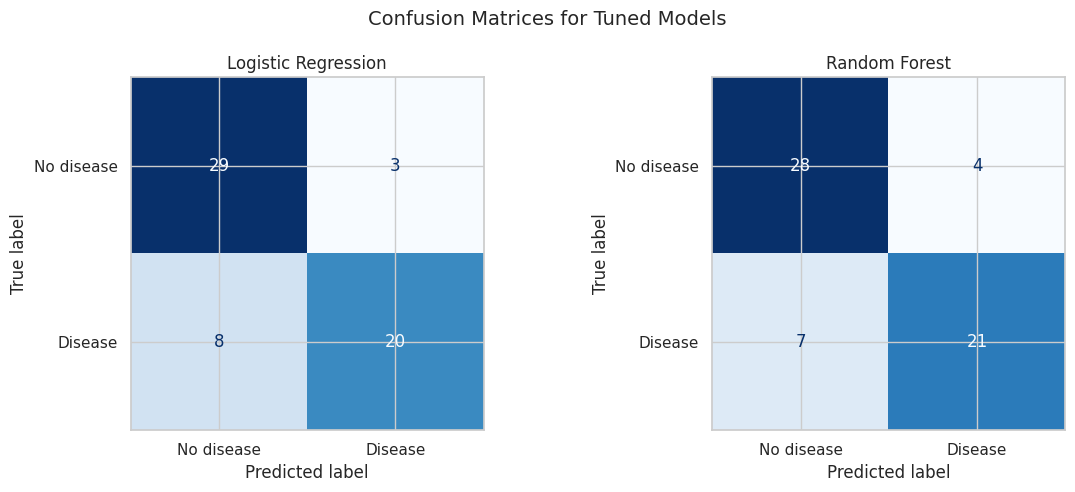

Saved: /content/MLOps-Assignment/screenshots/model_confusion_matrices.png


In [13]:
fig, axes = plt.subplots(1, len(searches), figsize=(12, 5))
if len(searches) == 1:
    axes = [axes]

for ax, (model_name, stored) in zip(axes, prediction_store.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        stored["predictions"],
        display_labels=["No disease", "Disease"],
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(model_name)

fig.suptitle("Confusion Matrices for Tuned Models", fontsize=14)
plt.tight_layout()
confusion_path = SCREENSHOTS_DIR / "model_confusion_matrices.png"
plt.savefig(confusion_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", confusion_path)

## 14. ROC curves

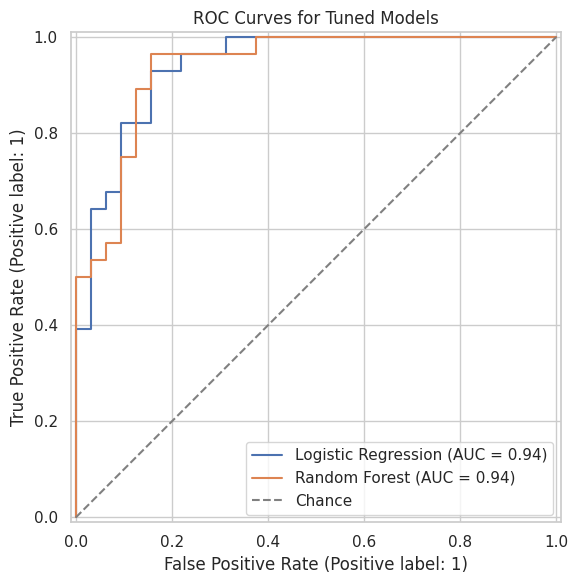

Saved: /content/MLOps-Assignment/screenshots/model_roc_curves.png


In [14]:
fig, ax = plt.subplots(figsize=(8, 6))

for model_name, stored in prediction_store.items():
    RocCurveDisplay.from_predictions(
        y_test,
        stored["probabilities"],
        name=model_name,
        ax=ax,
    )

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
ax.set_title("ROC Curves for Tuned Models")
ax.legend(loc="lower right")
plt.tight_layout()
roc_path = SCREENSHOTS_DIR / "model_roc_curves.png"
plt.savefig(roc_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", roc_path)

## 15. Select and save the final model

The final model is selected using cross-validated ROC-AUC from the training data, avoiding test-set-driven model selection. The saved artifact contains preprocessing and classification in one pipeline.

In [22]:
best_model_name = tuning_results.iloc[0]["model"]
best_model = searches[best_model_name].best_estimator_
best_cv_score = searches[best_model_name].best_score_

model_path = MODELS_DIR / "heart_disease_pipeline.joblib"
joblib.dump(best_model, model_path)

metadata = {
    "model_name": best_model_name,
    "selection_metric": "mean 5-fold stratified CV ROC-AUC on training data",
    "selection_score": float(best_cv_score),
    "best_parameters": searches[best_model_name].best_params_,
    "input_features": X.columns.tolist(),
    "continuous_features": continuous_features,
    "categorical_features": categorical_features,
    "target_mapping": {"0": "No disease", "1": "Disease"},
    "random_state": RANDOM_STATE,
}
metadata_path = MODELS_DIR / "heart_disease_pipeline_metadata.json"
with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2)

print("Selected model:", best_model_name)
print("Selection CV ROC-AUC:", round(best_cv_score, 4))
print("Saved model:", model_path)
print("Saved metadata:", metadata_path)

Selected model: Random Forest
Selection CV ROC-AUC: 0.9082
Saved model: /content/MLOps-Assignment/models/heart_disease_pipeline.joblib
Saved metadata: /content/MLOps-Assignment/models/heart_disease_pipeline_metadata.json


In [23]:
# ==========================================
# 18. Environment and Package Version Metadata
# ==========================================

import sklearn
import sys
import platform

environment_metadata = {
    "python_version": sys.version,
    "platform": platform.platform(),
    "pandas_version": pd.__version__,
    "numpy_version": np.__version__,
    "scikit_learn_version": sklearn.__version__,
    "joblib_version": joblib.__version__,
}

environment_metadata_path = (
    REPORTS_DIR / "environment_metadata.json"
)

with open(environment_metadata_path, "w", encoding="utf-8") as f:
    json.dump(environment_metadata, f, indent=2)

print("Saved:", environment_metadata_path)

environment_metadata

Saved: /content/MLOps-Assignment/reports/environment_metadata.json


{'python_version': '3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]',
 'platform': 'Linux-6.6.122+-x86_64-with-glibc2.39',
 'pandas_version': '2.2.3',
 'numpy_version': '2.1.3',
 'scikit_learn_version': '1.6.1',
 'joblib_version': '1.6.0'}

## 16. Model reload and prediction smoke test

This confirms that the serialized pipeline can be loaded independently and can return both a class and confidence value.

In [16]:
loaded_model = joblib.load(model_path)
sample_input = X_test.iloc[[0]].copy()
sample_prediction = int(loaded_model.predict(sample_input)[0])
sample_probability = float(loaded_model.predict_proba(sample_input)[0, 1])

print("Sample input:")
display(sample_input)
print("Predicted class:", sample_prediction)
print("Predicted label:", "Disease" if sample_prediction == 1 else "No disease")
print("Probability of disease:", round(sample_probability, 4))

Sample input:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
290,41,1,2,120,157,0,0,182,0,0.0,1,0.0,3.0


Predicted class: 0
Predicted label: No disease
Probability of disease: 0.0344


## 17. Permutation feature importance for the selected pipeline

Permutation importance measures the decrease in test-set ROC-AUC when each original input feature is shuffled. It works consistently for either selected model.

,feature,importance_mean,importance_std
11,ca,0.0502,0.0190
12,thal,0.0471,0.0255
1,sex,0.0138,0.0079
9,oldpeak,0.0128,0.0062
2,cp,0.0126,0.0141
7,thalach,0.0090,0.0053
8,exang,0.0081,0.0051
0,age,0.0043,0.0059
10,slope,0.0011,0.0077
5,fbs,0.0002,0.0009


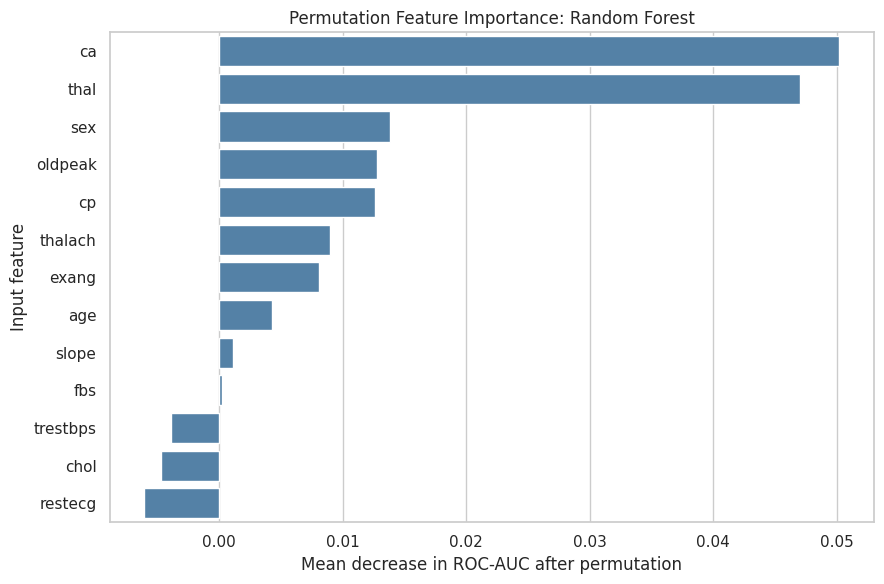

Saved: /content/MLOps-Assignment/screenshots/permutation_feature_importance.png


In [17]:
importance = permutation_importance(
    loaded_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=30,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": importance.importances_mean,
    "importance_std": importance.importances_std,
}).sort_values("importance_mean", ascending=False)

display(importance_df.round(4))
importance_df.to_csv(REPORTS_DIR / "permutation_feature_importance.csv", index=False)

plt.figure(figsize=(9, 6))
sns.barplot(
    data=importance_df,
    x="importance_mean",
    y="feature",
    color="steelblue",
)
plt.xlabel("Mean decrease in ROC-AUC after permutation")
plt.ylabel("Input feature")
plt.title(f"Permutation Feature Importance: {best_model_name}")
plt.tight_layout()
importance_path = SCREENSHOTS_DIR / "permutation_feature_importance.png"
plt.savefig(importance_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", importance_path)

## 18. Final artifact checklist

In [18]:
artifacts = [
    DATA_PATH,
    REPORTS_DIR / "baseline_cross_validation_results.csv",
    REPORTS_DIR / "hyperparameter_tuning_results.csv",
    REPORTS_DIR / "test_set_model_comparison.csv",
    REPORTS_DIR / "permutation_feature_importance.csv",
    SCREENSHOTS_DIR / "model_confusion_matrices.png",
    SCREENSHOTS_DIR / "model_roc_curves.png",
    SCREENSHOTS_DIR / "permutation_feature_importance.png",
    MODELS_DIR / "heart_disease_pipeline.joblib",
    MODELS_DIR / "heart_disease_pipeline_metadata.json",
]

artifact_check = pd.DataFrame({
    "artifact": [str(path) for path in artifacts],
    "exists": [path.exists() for path in artifacts],
})
display(artifact_check)

if artifact_check["exists"].all():
    print("All expected model-development artifacts are available.")
else:
    print("One or more artifacts are missing. Review the failed or skipped cells above.")

,artifact,exists
0,/content/MLOps-Assignment/data/processed/clean...,True
1,/content/MLOps-Assignment/reports/baseline_cro...,True
2,/content/MLOps-Assignment/reports/hyperparamet...,True
3,/content/MLOps-Assignment/reports/test_set_mod...,True
4,/content/MLOps-Assignment/reports/permutation_...,True
5,/content/MLOps-Assignment/screenshots/model_co...,True
6,/content/MLOps-Assignment/screenshots/model_ro...,True
7,/content/MLOps-Assignment/screenshots/permutat...,True
8,/content/MLOps-Assignment/models/heart_disease...,True
9,/content/MLOps-Assignment/models/heart_disease...,True


All expected model-development artifacts are available.


## Conclusion

This notebook:

- loaded and validated the processed heart-disease dataset;
- applied leakage-safe preprocessing inside scikit-learn pipelines;
- compared Logistic Regression and Random Forest with stratified cross-validation;
- tuned both models with `GridSearchCV`;
- evaluated tuned models using accuracy, precision, recall, F1, ROC-AUC, confusion matrices, and ROC curves;
- selected the final model using training cross-validation performance;
- saved one deployable preprocessing-plus-model pipeline and supporting metadata;
- verified serialized inference and generated permutation feature importance.

The next notebook should use MLflow to log parameters, metrics, plots, and model artifacts for these experiments.